# Telco Customer Churn Predictions


## EDA
#### Load DataSet

In [1]:
import pandas as pd
Customer=pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(Customer.info())
data=Customer.drop(columns=["Churn"])
target=Customer["Churn"]
data


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6


#### Identifying numerical and categorical features


our dataset contain a customer ID which considered as categorical values because it is in the form of a string while it is a suitable to verify id there is duplicates but for our model 
it is irrelevant because it does not describe a customer behavior so it will not be considered an interesting feature for traing so we will not use it 



In [2]:
from sklearn.compose import make_column_selector as Selector
numerical_columns=Selector(dtype_exclude=object)(data)
categorical_columns=Selector(dtype_include=object)(data)
categorical_columns.remove("customerID")
numerical_columns , categorical_columns

(['SeniorCitizen', 'tenure', 'MonthlyCharges'],
 ['gender',
  'Partner',
  'Dependents',
  'PhoneService',
  'MultipleLines',
  'InternetService',
  'OnlineSecurity',
  'OnlineBackup',
  'DeviceProtection',
  'TechSupport',
  'StreamingTV',
  'StreamingMovies',
  'Contract',
  'PaperlessBilling',
  'PaymentMethod',
  'TotalCharges'])

for citizen values which have categorical meaning but they are stored as integer i choose to leave it as it is to avoid an extrastep of preprocessing before training because the data for training must be numerical and not string texts 

#### Inspecting values for missing values and duplicates
##### Missing values

In [3]:
(data.isnull().sum() , target.isnull().sum())

(customerID          0
 gender              0
 SeniorCitizen       0
 Partner             0
 Dependents          0
 tenure              0
 PhoneService        0
 MultipleLines       0
 InternetService     0
 OnlineSecurity      0
 OnlineBackup        0
 DeviceProtection    0
 TechSupport         0
 StreamingTV         0
 StreamingMovies     0
 Contract            0
 PaperlessBilling    0
 PaymentMethod       0
 MonthlyCharges      0
 TotalCharges        0
 dtype: int64,
 np.int64(0))

When inspecting missing value pandas search for null markers but if we have a empty string it will not be considered as empty there for we must inspect our rows string values

In [4]:
Empty=data[categorical_columns].apply(lambda col : col.astype(str).str.strip().eq("") ).sum()
print(Empty)

gender               0
Partner              0
Dependents           0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
TotalCharges        11
dtype: int64


In [5]:
Empty=data[categorical_columns].apply(lambda col : col.astype(str).str.strip().eq("") ).any(axis=1)
data[Empty]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,


##### Total charges feature
we have two problems with the value of total charges column 

it is a numerical value but pandas has read it as str which is due to the empty values in the column who forces pandas to consider it as a text

empty values considred as empty strings which must be imputed with a meaningfull value

In [6]:
data["TotalCharges"]=pd.to_numeric(data["TotalCharges"].astype(str).str.strip() , errors="coerce")
print(data["TotalCharges"].dtype)
numerical_columns=Selector(dtype_exclude=object)(data)
categorical_columns=Selector(dtype_include=object)(data)
categorical_columns.remove("customerID")

numerical_columns , categorical_columns


float64


(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'],
 ['gender',
  'Partner',
  'Dependents',
  'PhoneService',
  'MultipleLines',
  'InternetService',
  'OnlineSecurity',
  'OnlineBackup',
  'DeviceProtection',
  'TechSupport',
  'StreamingTV',
  'StreamingMovies',
  'Contract',
  'PaperlessBilling',
  'PaymentMethod'])

as we can observe tenure value which means for how long the client was a client for the company is 0 for all empty Total charges

lets inspect our dataset if there is rows with tenure value = 0 and have a valid total charges

In [7]:
data[data["tenure"] == 0 ]['TotalCharges'].notnull()

488     False
753     False
936     False
1082    False
1340    False
3331    False
3826    False
4380    False
5218    False
6670    False
6754    False
Name: TotalCharges, dtype: bool

as we can see all the values with tenure 0 have a an empty Total Charges value 

teh most meaningfull value would be 0 to replace this non valid values but the imputation should be in the training set to prevent data leackage

##### Duplicates

In [8]:

data.duplicated(keep=False).sum(), data["customerID"].duplicated().sum()

(np.int64(0), np.int64(0))

#### Target distribution

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

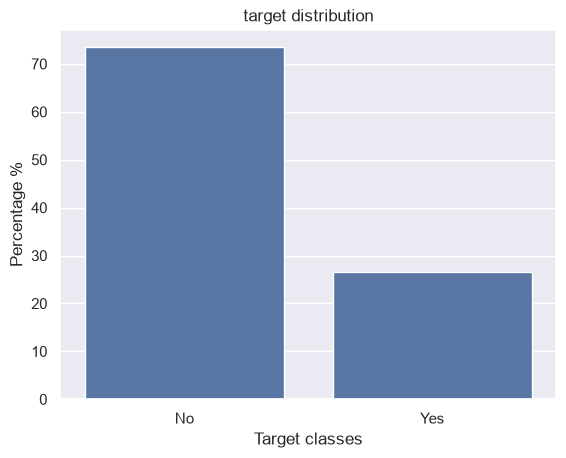

In [9]:
targetDistribution=target.value_counts(normalize=True)*100
import matplotlib.pyplot as plt 
import seaborn as sns 
sns.set()

sns.barplot(x=targetDistribution.index , y=targetDistribution.values ,fill=True )
plt.xlabel("Target classes")
plt.ylabel("Percentage %")
plt.title("target distribution")
targetDistribution


#### Observations and exploratory analysis
most  of our features are categorical

we have an imbalanced Dataset with  74 for for negative churn and 26 for postive values of churn



##### tenure vs Churn

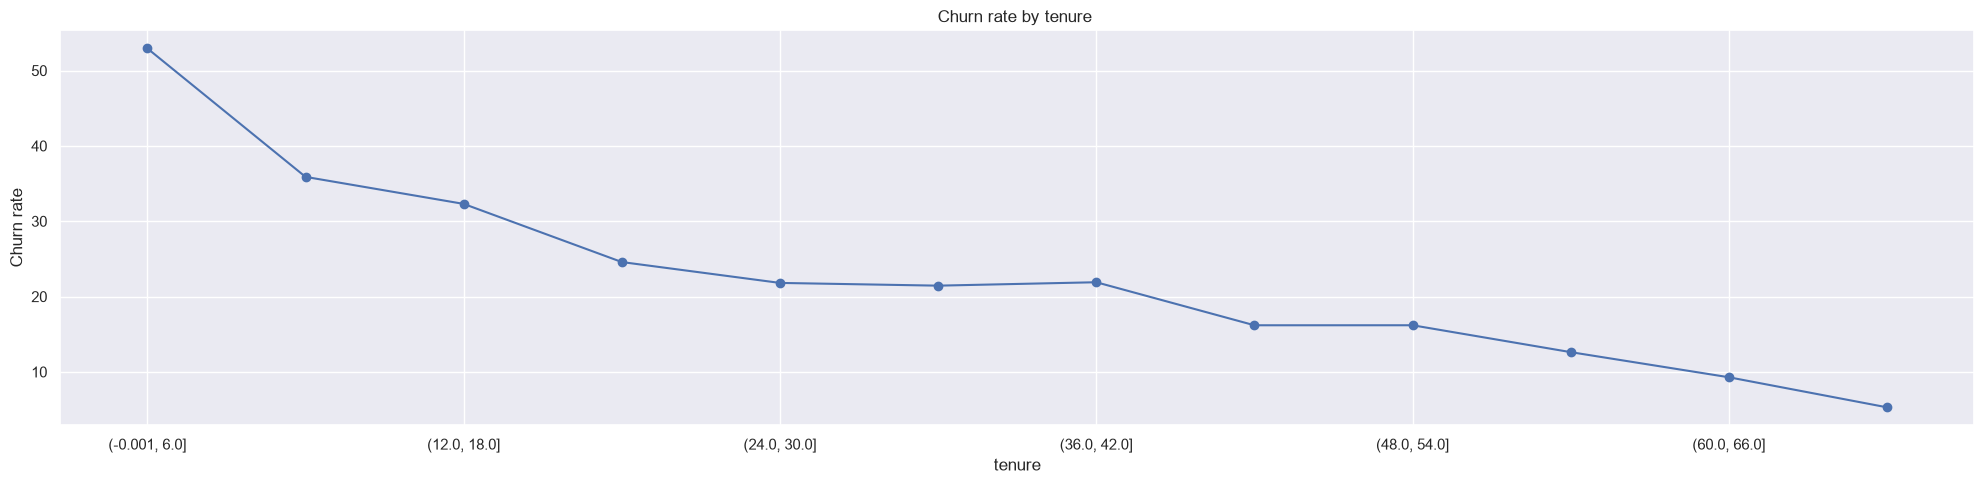

In [10]:
df=Customer.copy()
df["tenure_group"]=pd.cut(
    df["tenure"],
    bins=range(0 , 100 , 6 ),
    include_lowest=True
)

churn_rate =df.groupby("tenure_group" , observed=True)["Churn"].apply(
    lambda x : (x=='Yes').mean()*100
)

plt.figure(figsize=(20,5))
churn_rate.plot(
    kind="line",
    marker="o"
)

plt.xlabel("tenure")
plt.ylabel("Churn rate")
plt.title("Churn rate by tenure ")


#plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

as we can see above the highest values are for the cliet with the least tenure month which make us understand that the majority of the subscription cancellation appears in the first months with the time passing the client tend less to churn

customers with shorter tenure tend to have a higher observed churn rate.

##### Contract vs Churn

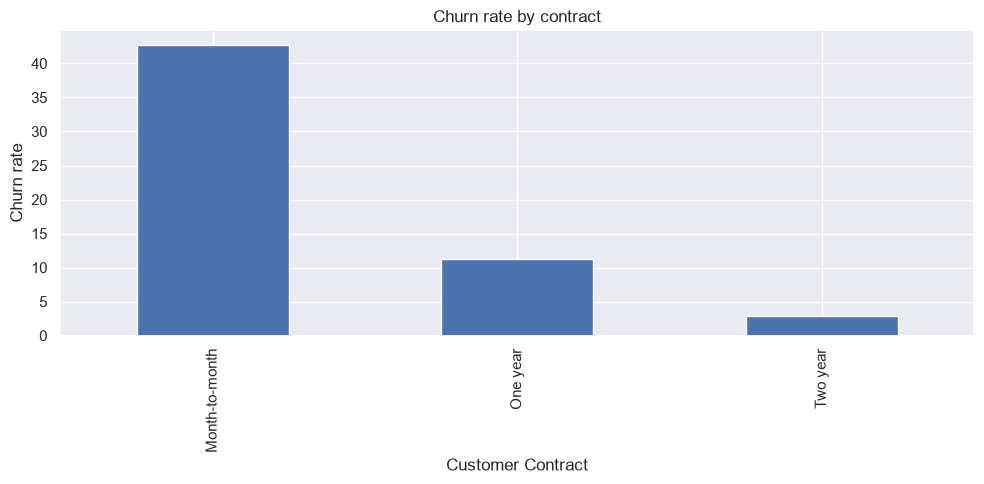

In [11]:
churn_rate =Customer.groupby("Contract" , observed=True)["Churn"].apply(
    lambda x : (x=='Yes').mean()*100
)

plt.figure(figsize=(10,5))
churn_rate.plot(
    kind="bar",
)

plt.xlabel("Customer Contract")
plt.ylabel("Churn rate")
plt.title("Churn rate by contract")


#plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##### Churn vs Monthly charges

                             count  churnRate
Monthlycharges_group                         
(18.148999999999997, 38.35]   1797  11.407902
(38.35, 58.45]                1005  26.965174
(58.45, 78.55]                1367  29.480614
(78.55, 98.65]                1826  36.966046
(98.65, 118.75]               1048  30.057252


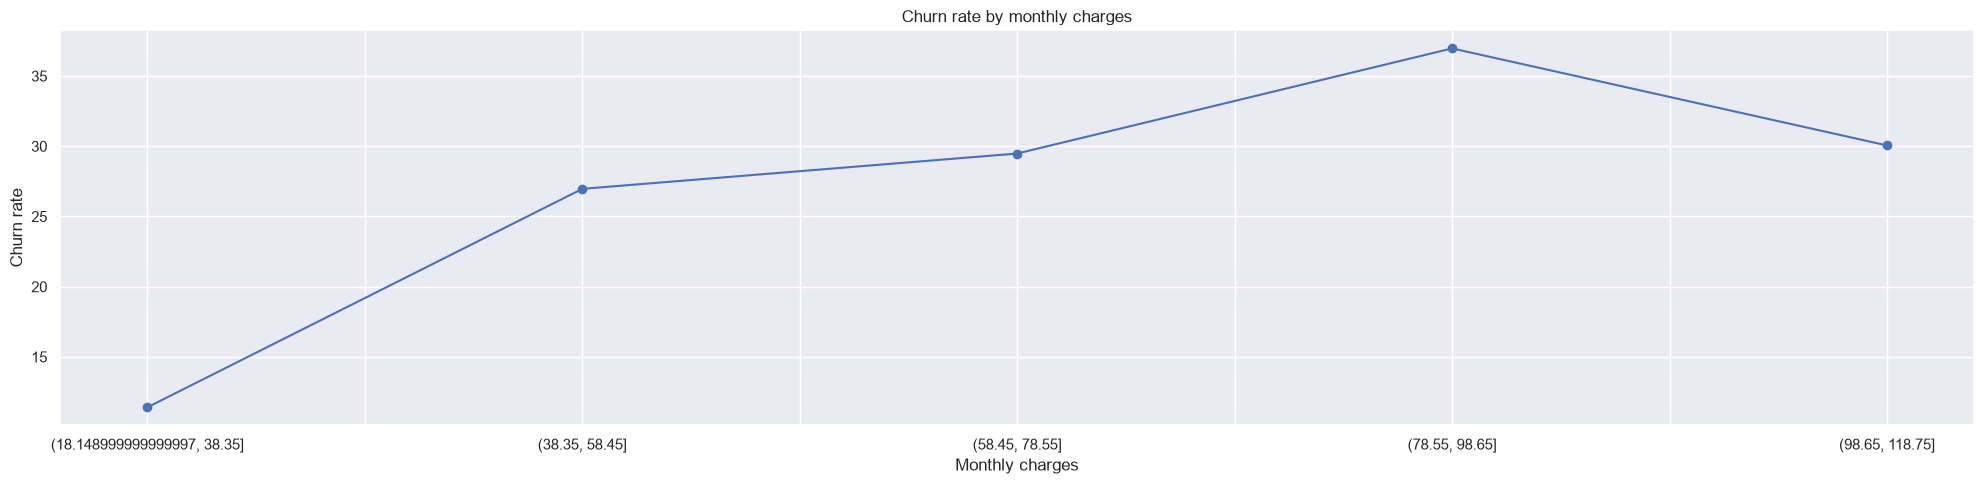

In [12]:

df=Customer.copy()
df["Monthlycharges_group"]=pd.cut(
    df["MonthlyCharges"],
    bins=5,
    include_lowest=True
)

churn_rate =df.groupby("Monthlycharges_group" , observed=True)["Churn"].apply(
    lambda x : (x=='Yes').mean()*100
)
c=df.groupby("Monthlycharges_group").size()
MonthlyChargesAnalysis=pd.DataFrame(
    {
        "count":c ,
        "churnRate" : churn_rate
    }
)
print(MonthlyChargesAnalysis)
plt.figure(figsize=(20,5))
churn_rate.plot(
    kind="line",
    marker="o"
)

plt.xlabel("Monthly charges")
plt.ylabel("Churn rate")
plt.title("Churn rate by monthly charges")


#plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The analysis reveals an association between monthly charges and customer churn. Customers in the lowest monthly charge interval have an observed churn rate of approximately 11%, compared with around 37% in the 78–99 interval. However, this relationship is not strictly increasing, as the highest-charge group exhibits a lower churn rate of approximately 30%. All intervals contain more than 1,000 customers, supporting relatively stable descriptive estimates. Further analysis would be required to determine whether this association persists after accounting for other customer characteristics.

#### Churn vs total charges

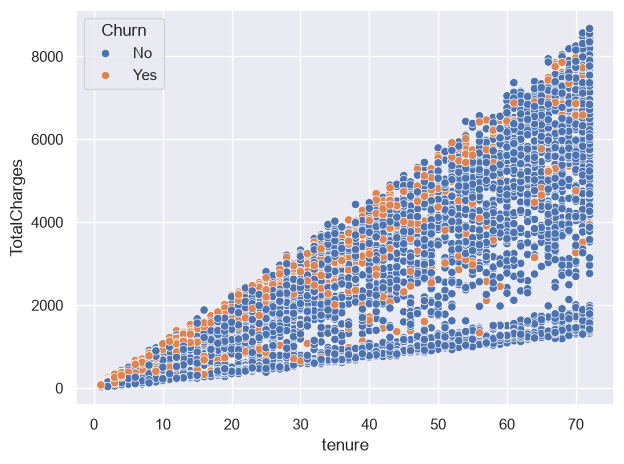

In [13]:
df=Customer.copy()
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"].astype(str).str.strip() , errors="coerce")
sns.scatterplot(df, y=df["TotalCharges"] ,x=df["tenure"] ,hue=df['Churn'])
#plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

as we can see that the relationship is approximativly linear and we can see also for customer with the same tenure teh total charge vary considrably 

Longer-tenure customers generally have higher accumulated charges, but tenure alone does not explain all the variation in total charges.

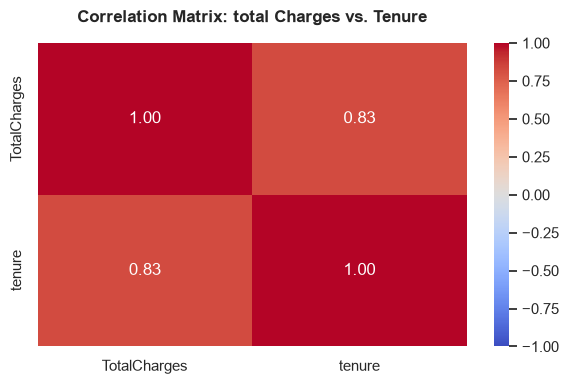

In [14]:
PearsonCorr=df[["TotalCharges" , "tenure"]].corr(method="pearson")
plt.figure(figsize=(6, 4))
sns.heatmap(
    PearsonCorr, 
    annot=True,          # Displays the actual correlation numbers on the blocks
    cmap="coolwarm",     # Blue for negative, red for positive correlation
    vmin=-1, vmax=1,     # Anchors the color scale to the Pearson limits
    fmt=".2f"            # Rounds the display numbers to 2 decimal places
)
plt.title("Correlation Matrix: total Charges vs. Tenure", weight="bold", pad=15)
plt.tight_layout()
plt.show()

the correlation suggests that total charges and tenure have a postive linear relashionship which confirms our conclusions earlier

                MonthlyCharges  tenure
MonthlyCharges          1.0000  0.2479
tenure                  0.2479  1.0000


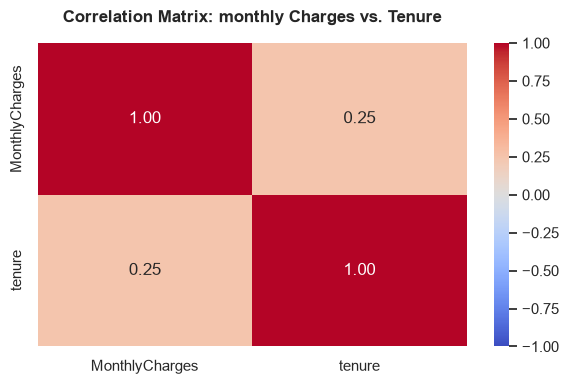

In [15]:
PearsonCorr=df[["MonthlyCharges" , "tenure"]].corr(method="pearson")
print(PearsonCorr)
plt.figure(figsize=(6, 4))
sns.heatmap(
    PearsonCorr, 
    annot=True,          # Displays the actual correlation numbers on the blocks
    cmap="coolwarm",     # Blue for negative, red for positive correlation
    vmin=-1, vmax=1,     # Anchors the color scale to the Pearson limits
    fmt=".2f"            # Rounds the display numbers to 2 decimal places
)
plt.title("Correlation Matrix: monthly Charges vs. Tenure", weight="bold", pad=15)
plt.tight_layout()
plt.show()

we have a 0.25 value of correlation which is positive but it reflects that these two feature does not exactly follow a linear relatioship

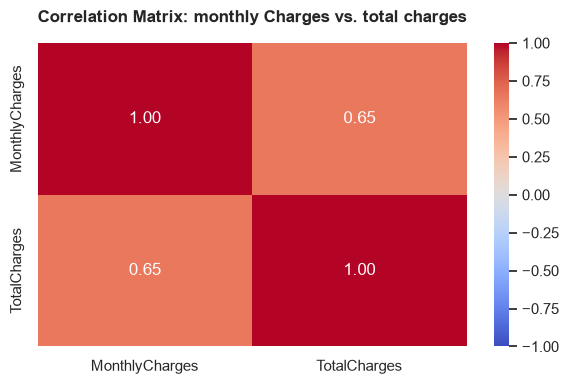

In [16]:
PearsonCorr=df[["MonthlyCharges" , "TotalCharges"]].corr(method="pearson")
plt.figure(figsize=(6, 4))
sns.heatmap(
    PearsonCorr, 
    annot=True,          # Displays the actual correlation numbers on the blocks
    cmap="coolwarm",     # Blue for negative, red for positive correlation
    vmin=-1, vmax=1,     # Anchors the color scale to the Pearson limits
    fmt=".2f"            # Rounds the display numbers to 2 decimal places
)
plt.title("Correlation Matrix: monthly Charges vs. total charges", weight="bold", pad=15)
plt.tight_layout()
plt.show()

we have a 0.65 correlation values which indecates a moderate to strong linear relationship between monthly charges and total charges

### Exploratory Data Analysis — Conclusions

**1. Target distribution and class imbalance**

The dataset contains 7,043 customers. Approximately 73.5% did not churn, while 26.5% churned.

This indicates a moderate class imbalance. Therefore, accuracy alone may not be sufficient to evaluate our classification models. Metrics such as precision, recall, F1-score, and ROC-AUC should also be considered.

**2. Customer tenure and churn**

Customers with shorter tenure generally exhibit higher observed churn rates, while customers with longer tenure tend to have lower churn rates.

This suggests that tenure may be an informative predictor of customer churn. However, this relationship does not establish causation.

**3. Monthly charges and churn**

The analysis reveals a nonlinear association between monthly charges and churn.

Customers in the lowest monthly-charge interval have a churn rate of approximately 11.4%, compared with 37% for customers paying between 78.55 and 98.65.

However, the churn rate decreases to approximately 30.1% in the highest-charge interval.

This suggests that MonthlyCharges may contain useful predictive information, although its relationship with churn is not strictly increasing.

**4. Relationships between numerical features**

The correlation analysis reveals:

- Tenure and TotalCharges: strong positive correlation (r ≈ 0.826).
- MonthlyCharges and TotalCharges: moderately strong positive correlation (r ≈ 0.65).
- Tenure and MonthlyCharges: weak positive correlation (r ≈ 0.248).

These findings indicate that TotalCharges shares substantial information with tenure and monthly charges.

However, correlations between features do not establish their individual predictive importance.

**5. Data quality and preprocessing requirements**

The dataset contains 11 missing values in TotalCharges, all associated with customers whose tenure is zero months.

A zero-imputation strategy has been identified as a reasonable assumption, subject to the interpretation of the billing data.

The customerID column will be excluded from predictive features because it functions as an identifier rather than a meaningful customer characteristic.

Numerical and categorical features will require appropriate preprocessing before model training.

**6. Implications for machine learning**

The EDA identifies tenure, monthly charges, and total charges as potentially informative features for customer churn prediction.

However, their actual predictive contributions remain to be evaluated.

The next stage will focus on data splitting, preprocessing pipelines, model training, and cross-validation. Comparing model

## Prepreocessing

#### Splitting the dataset

we need to split the dataset into training and test splits which will be used to train and test the model performances because we have an imbalanced classes we will use stratify to ensure that the portion of postive and negative classes are maintained in the two splits

In [17]:
from sklearn.model_selection import train_test_split
data=data.drop(columns=["customerID"])
XTrain ,XTest , YTrain ,YTest = train_test_split(data ,target , train_size= 0.8 , stratify=target , random_state=0)
print(XTrain.shape , XTest.shape , YTrain.shape , YTest.shape)
(YTrain == "Yes").mean() , (YTest== "Yes").mean()

(5634, 19) (1409, 19) (5634,) (1409,)


(np.float64(0.2653532126375577), np.float64(0.2654364797728886))

#### Preprocessing

for our preprocessing we will use pipelines to prevent dataleakage and have a reproducable automatique preprocessing 

categorical data : we will use a one hot encoder for our dataset because we do not have ordinal categories feature 

numerical data : standard scaler to scale our data to a mean of 0 and an standard deviation of 1 

missing data : 0 value imputing fro non valid  TotalCharges feature as disscused earlier 

Senior Citizen : as we have seen senior citizen must be passed unchanged because if we convert it to a category it will be recoverted to binary callsses soo we will leave it as it is

In [18]:
from sklearn.pipeline import make_pipeline ,Pipeline
from sklearn.preprocessing import OneHotEncoder , StandardScaler 
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
if "SeniorCitizen" in numerical_columns :
    numerical_columns.remove("SeniorCitizen")
binary_columns = ["SeniorCitizen"]
Numericpreprocessing= make_pipeline(
    SimpleImputer(strategy="constant" , fill_value= 0 ),
    StandardScaler()
)
preprocessing= make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore"),categorical_columns),
    (Numericpreprocessing,numerical_columns),
    ("passthrough" , binary_columns)
)
XTrainPre=preprocessing.fit_transform(XTrain)

features=preprocessing.get_feature_names_out()
XTrainP=pd.DataFrame(XTrainPre , columns=features)
print(XTrainP.shape )
empty=XTrainP.isnull().sum()
print(empty)
XTrainP


(5634, 45)
onehotencoder__gender_Female                              0
onehotencoder__gender_Male                                0
onehotencoder__Partner_No                                 0
onehotencoder__Partner_Yes                                0
onehotencoder__Dependents_No                              0
onehotencoder__Dependents_Yes                             0
onehotencoder__PhoneService_No                            0
onehotencoder__PhoneService_Yes                           0
onehotencoder__MultipleLines_No                           0
onehotencoder__MultipleLines_No phone service             0
onehotencoder__MultipleLines_Yes                          0
onehotencoder__InternetService_DSL                        0
onehotencoder__InternetService_Fiber optic                0
onehotencoder__InternetService_No                         0
onehotencoder__OnlineSecurity_No                          0
onehotencoder__OnlineSecurity_No internet service         0
onehotencoder__OnlineSecurity

,onehotencoder__gender_Female,onehotencoder__gender_Male,onehotencoder__Partner_No,onehotencoder__Partner_Yes,onehotencoder__Dependents_No,onehotencoder__Dependents_Yes,onehotencoder__PhoneService_No,onehotencoder__PhoneService_Yes,onehotencoder__MultipleLines_No,onehotencoder__MultipleLines_No phone service,...,onehotencoder__PaperlessBilling_No,onehotencoder__PaperlessBilling_Yes,onehotencoder__PaymentMethod_Bank transfer (automatic),onehotencoder__PaymentMethod_Credit card (automatic),onehotencoder__PaymentMethod_Electronic check,onehotencoder__PaymentMethod_Mailed check,pipeline__tenure,pipeline__MonthlyCharges,pipeline__TotalCharges,passthrough__SeniorCitizen
0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.363266,0.193982,0.285152,0.0
1,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.016103,-1.515002,-0.512822,0.0
2,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.404069,0.715987,0.655370,0.0
3,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,-1.105616,0.699362,-0.820119,0.0
4,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,1.424126,0.042700,0.918274,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,-0.126361,-0.303086,-0.279729,0.0
5630,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,-1.268825,0.368538,-0.964469,0.0
5631,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.812091,0.893867,1.102430,0.0
5632,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,-0.452779,1.179806,-0.114677,0.0


as we can see our pipeline works correctly with a garding all the rows as data before preprocessing and with no empty values 

In [19]:
XTestPre=preprocessing.transform(XTest)

features=preprocessing.get_feature_names_out()
XTestP=pd.DataFrame(XTestPre , columns=features)
print(XTestP.shape )
empty=XTestP.isnull().sum()
print(empty)

(1409, 45)
onehotencoder__gender_Female                              0
onehotencoder__gender_Male                                0
onehotencoder__Partner_No                                 0
onehotencoder__Partner_Yes                                0
onehotencoder__Dependents_No                              0
onehotencoder__Dependents_Yes                             0
onehotencoder__PhoneService_No                            0
onehotencoder__PhoneService_Yes                           0
onehotencoder__MultipleLines_No                           0
onehotencoder__MultipleLines_No phone service             0
onehotencoder__MultipleLines_Yes                          0
onehotencoder__InternetService_DSL                        0
onehotencoder__InternetService_Fiber optic                0
onehotencoder__InternetService_No                         0
onehotencoder__OnlineSecurity_No                          0
onehotencoder__OnlineSecurity_No internet service         0
onehotencoder__OnlineSecurity

the preprocessing for the test dataset is excuted correctly

## Model Training

because we have an imbalanced dataset accuracy whil not be a sufficient metric to evaluate our modele we will use f1 score with tracking precision and recall

### DummyClassifier 

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate , StratifiedKFold
from sklearn.metrics import make_scorer , precision_score ,recall_score,f1_score , roc_auc_score

safeprecision=make_scorer(precision_score,pos_label='Yes' , zero_division = 0)
saferecall=make_scorer(recall_score,pos_label='Yes' , zero_division = 0)
safef1=make_scorer(f1_score,pos_label='Yes' , zero_division = 0)
saferoc=make_scorer(roc_auc_score, response_method="predict_proba")

DummyModel=make_pipeline(
    preprocessing,
    DummyClassifier(strategy="most_frequent" )
)

cv=StratifiedKFold(n_splits=5 ,shuffle=True , random_state=42)  
scoring={"f1":safef1 , "recall":saferecall , "precision":safeprecision , "accuracy":"accuracy"}

Scores=cross_validate(DummyModel , XTrain , YTrain , cv=cv ,scoring=scoring)

Scores=pd.DataFrame(Scores).drop(columns=["fit_time","score_time"])
Scores.mean() , Scores.std()

(test_f1           0.000000
 test_recall       0.000000
 test_precision    0.000000
 test_accuracy     0.734647
 dtype: float64,
 test_f1           0.000000
 test_recall       0.000000
 test_precision    0.000000
 test_accuracy     0.000105
 dtype: float64)

our dummy classifier with a strategie of most frequent it calculates the most frequent class which is No churn and applies it on all the rows of the dataset without learning any feature  our accuracy score is 73% which reflects the percentage of no churn values in the target  for recall and precision we have zero values because ther is no postive preduiction of churn since bothe precision and recall are zeros the f1 score collap^ses to zero 

### Logistic regression 


In [21]:
from sklearn.linear_model import LogisticRegression

RegressionModel=make_pipeline(
    preprocessing,
    LogisticRegression()
)

cv=StratifiedKFold(n_splits=5 ,shuffle=True , random_state=42)  
scoring={"f1":safef1 , "recall":saferecall , "precision":safeprecision , "accuracy":"accuracy"}

Scores=cross_validate(RegressionModel , XTrain , YTrain , cv=cv ,scoring=scoring)

Scores=pd.DataFrame(Scores).drop(columns=["fit_time","score_time"])
Scores.mean() , Scores.std()

(test_f1           0.604557
 test_recall       0.554515
 test_precision    0.664828
 test_accuracy     0.807595
 dtype: float64,
 test_f1           0.024581
 test_recall       0.026798
 test_precision    0.025128
 test_accuracy     0.011222
 dtype: float64)

Our regression model performs better than our baseline model as we can see all the metrics scores are higher that the dummy classifier accuracy :80% ,recall:55% , precision:66% , f1:60%

recall is the percentage of postive value correctly predicted our regression model predicted 55% of these values that means there is 45% of actual churners were predicted as a non churner 

### Decision tree

In [22]:
from sklearn.tree import DecisionTreeClassifier

DecisionTreeModel=make_pipeline(
    preprocessing,
    DecisionTreeClassifier(random_state=42)
)

cv=StratifiedKFold(n_splits=5 ,shuffle=True , random_state=42)  
scoring={"f1":safef1 , "recall":saferecall , "precision":safeprecision , "accuracy":"accuracy"}

Scores=cross_validate(DecisionTreeModel , XTrain , YTrain , cv=cv ,scoring=scoring)

Scores=pd.DataFrame(Scores).drop(columns=["fit_time","score_time"])
Scores.mean() , Scores.std()

(test_f1           0.494371
 test_recall       0.500334
 test_precision    0.488836
 test_accuracy     0.728789
 dtype: float64,
 test_f1           0.027832
 test_recall       0.036606
 test_precision    0.020806
 test_accuracy     0.011562
 dtype: float64)

The Decision Tree performs worse than Logistic Regression across all evaluation metrics. Although its accuracy is slightly lower than the DummyClassifier baseline, it identifies approximately 51% of actual churners, whereas the baseline identifies none

we might suspect an overfiiting because of the no restriction on the complexity of the tree

### Random forest

In [23]:
from sklearn.ensemble import RandomForestClassifier

RandomForestModel=make_pipeline(
    preprocessing,
    RandomForestClassifier(random_state=42)
)

cv=StratifiedKFold(n_splits=5 ,shuffle=True , random_state=42)  
scoring={"f1":safef1 , "recall":saferecall , "precision":safeprecision , "accuracy":"accuracy"}

Scores=cross_validate(RandomForestModel , XTrain , YTrain , cv=cv ,scoring=scoring)

Scores=pd.DataFrame(Scores).drop(columns=["fit_time","score_time"])
Scores.mean() , Scores.std()

(test_f1           0.549955
 test_recall       0.487625
 test_precision    0.632292
 test_accuracy     0.788780
 dtype: float64,
 test_f1           0.030632
 test_recall       0.041193
 test_precision    0.022154
 test_accuracy     0.009898
 dtype: float64)

The random forest classifier performs better thatn the cesion tree an all metrics accept recal

Random Forest combines predictions from trees trained on different samples and with randomized feature selection. Aggregating these predictions can reduce variance and improve generalization compared with a single unrestricted decision tree.

### Gradient boosting

In [24]:
from sklearn.ensemble import HistGradientBoostingClassifier

GradientBoostModel=make_pipeline(
    preprocessing,
    HistGradientBoostingClassifier(random_state=42)
)

cv=StratifiedKFold(n_splits=5 ,shuffle=True , random_state=42)  
scoring={"f1":safef1 , "recall":saferecall , "precision":safeprecision , "accuracy":"accuracy"}

Scores=cross_validate(GradientBoostModel , XTrain , YTrain , cv=cv ,scoring=scoring)

Scores=pd.DataFrame(Scores).drop(columns=["fit_time","score_time"])
Scores.mean() , Scores.std()

(test_f1           0.563844
 test_recall       0.510368
 test_precision    0.631077
 test_accuracy     0.790910
 dtype: float64,
 test_f1           0.026400
 test_recall       0.037288
 test_precision    0.017501
 test_accuracy     0.008684
 dtype: float64)

Gradient Boosting achieves higher accuracy, recall and F1-score than Random Forest and Decision Tree. However, Logistic Regression remains the best-performing model across the evaluation metrics considered

"Gradient Boosting builds trees sequentially. Each new tree is trained to improve the predictions of the current ensemble by following the gradient of a loss function. Unlike Random Forest, which aggregates largely independent trees, Gradient Boosting progressively updates the model."

## Hyperparamatere tuning 
for our hyperparamatere tuning we will choose two model from the created baseline models which are logistic regression and gradient noosting because they are the most powerfull models and they  provides different approaches

#### Logistic Regression

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
RegressionModel=make_pipeline(
    preprocessing,
    LogisticRegression()
)
C={
    "logisticregression__C" : [0.1,1,10]
}

cv=StratifiedKFold(n_splits=5 ,shuffle=True , random_state=42)  
scoring={"f1":safef1 , "recall":saferecall , "precision":safeprecision , "accuracy":"accuracy"}

TunnedModel=GridSearchCV(RegressionModel , param_grid=C, cv=cv ,scoring=safef1)
TunnedModel.fit(XTrain , YTrain)
Results=pd.DataFrame(TunnedModel.cv_results_)
ColumnsToKeep=[
    'param_logisticregression__C',  
    'mean_test_score',              
    'std_test_score',               
    'rank_test_score'  
]
Results[ColumnsToKeep].sort_values(by="rank_test_score")



,param_logisticregression__C,mean_test_score,std_test_score,rank_test_score
2,10.0,0.604825,0.023124,1
1,1.0,0.604557,0.021986,2
0,0.1,0.596409,0.021872,3


as we can see the f1 score of teh three paramters is nearly the same with a slight better score for a high c = 10 (weak regularized model)  but the difference between c=1 and c=10 was negligable

Similar F1-scores for several values of C may indicate that the model's predictions are relatively insensitive to the tested regularization strengths.

In [26]:

GradientBoostModel=make_pipeline(
    preprocessing,
    HistGradientBoostingClassifier(random_state=42)
)

cv=StratifiedKFold(n_splits=5 ,shuffle=True , random_state=42)  
scoring={"f1":safef1 , "recall":saferecall , "precision":safeprecision , "accuracy":"accuracy"}
param_grid={
    "histgradientboostingclassifier__learning_rate" : [0.03,0.01],
    "histgradientboostingclassifier__max_leaf_nodes" : [15,31],
    "histgradientboostingclassifier__max_depth" : [3,8],
    "histgradientboostingclassifier__max_iter" : [100 , 200],

}

TunnedModel=GridSearchCV(GradientBoostModel , param_grid=param_grid, cv=cv ,scoring=safef1 , n_jobs=2)
TunnedModel.fit(XTrain , YTrain)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'histgradientboostingclassifier__learning_rate': [0.03, 0.01], 'histgradientboostingclassifier__max_depth': [3, 8], 'histgradientboostingclassifier__max_iter': [100, 200], 'histgradientboostingclassifier__max_leaf_nodes': [15, 31]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(f...ro_division=0)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for a

In [27]:
Results=pd.DataFrame(TunnedModel.cv_results_)


In [28]:
ColumnsToKeep=[
    "param_histgradientboostingclassifier__learning_rate",
    "param_histgradientboostingclassifier__max_leaf_nodes",
    "param_histgradientboostingclassifier__max_iter",
    "param_histgradientboostingclassifier__max_depth",
    'mean_test_score',              
    'std_test_score',               
    'rank_test_score'  
]
Results[ColumnsToKeep].sort_values(by="rank_test_score")

,param_histgradientboostingclassifier__learning_rate,param_histgradientboostingclassifier__max_leaf_nodes,param_histgradientboostingclassifier__max_iter,param_histgradientboostingclassifier__max_depth,mean_test_score,std_test_score,rank_test_score
3,0.03,31,200,3,0.587814,0.025346,1
2,0.03,15,200,3,0.587814,0.025346,1
6,0.03,15,200,8,0.581733,0.028929,3
4,0.03,15,100,8,0.577099,0.028708,4
7,0.03,31,200,8,0.577082,0.022299,5
5,0.03,31,100,8,0.569663,0.031033,6
0,0.03,15,100,3,0.561880,0.032445,7
1,0.03,31,100,3,0.561880,0.032445,7
14,0.01,15,200,8,0.554153,0.026891,9
15,0.01,31,200,8,0.550690,0.025140,10


Our f1 score mean varies from 0.28 rto 0.58 thye best score mean value collides with the followin paramaters 

learning rate : 0.03 
max_leaf_nodes : 31 -15 sqame f1 score at max depth 3 
max iter : 200
max depth : 3

we can observe that the difference between first 5 mean scores is very small and shares these attribute 
small learening rate  high max iter variant max leaf nodes and variant max depth 

we establish a 2.4% higher score that the untuned gradient boosting model 

the best performance remains from the logistic regression tuned model


for bothy our modele we have the best models are 
Logistic regression  : c=10  f1score=0.604825	
gradient boost : learning rate : 0.03   max_leaf_nodes : 31  max iter : 200 max depth : 3 with a score of 0.587814	

In [29]:


RegressionModel=make_pipeline(
    preprocessing,
    LogisticRegression(C=10)
)

cv=StratifiedKFold(n_splits=5 ,shuffle=True , random_state=42)  
scoring={"f1":safef1 , "recall":saferecall , "precision":safeprecision , "ROC-AUC":saferoc}

Scores=cross_validate(RegressionModel , XTrain , YTrain , cv=cv ,scoring=scoring)

Scores=pd.DataFrame(Scores).drop(columns=["fit_time","score_time"])
Scores.mean() , Scores.std()

(test_f1           0.604825
 test_recall       0.555853
 test_precision    0.663607
 test_ROC-AUC      0.843387
 dtype: float64,
 test_f1           0.025854
 test_recall       0.029951
 test_precision    0.023166
 test_ROC-AUC      0.014888
 dtype: float64)

In [30]:
GradientBoostModel=make_pipeline(
    preprocessing,
    HistGradientBoostingClassifier(learning_rate=0.03,max_leaf_nodes=31,max_iter=200,max_depth=3,random_state=42)
)

cv=StratifiedKFold(n_splits=5 ,shuffle=True , random_state=42)  
scoring={"f1":safef1 , "recall":saferecall , "precision":safeprecision , "ROC-AUC":saferoc}

Scores=cross_validate(GradientBoostModel , XTrain , YTrain , cv=cv ,scoring=scoring)

Scores=pd.DataFrame(Scores).drop(columns=["fit_time","score_time"])
Scores.mean() , Scores.std()

(test_f1           0.587814
 test_recall       0.526421
 test_precision    0.666702
 test_ROC-AUC      0.847013
 dtype: float64,
 test_f1           0.028338
 test_recall       0.039966
 test_precision    0.014245
 test_ROC-AUC      0.012432
 dtype: float64)

Logistic Regression achieves slightly higher F1-score and recall, while Gradient Boosting obtains slightly better precision and ROC-AUC. Since F1-score is our primary evaluation metric, Logistic Regression is currently our preferred candidate.

OC-AUC scores are both approximately 0.84.

This indicates that both models demonstrate useful ability to rank churners above non-churners across different classification thresholds.

because our primary selection score is f1 score we will choose the logistic regressor with a c value of 10 as our prediction model 

## Model Evaluation

F1           0.598561
Recall       0.556150
Precision    0.647975
ROC-AUC      0.851613
accuracy     0.801987
dtype: float64


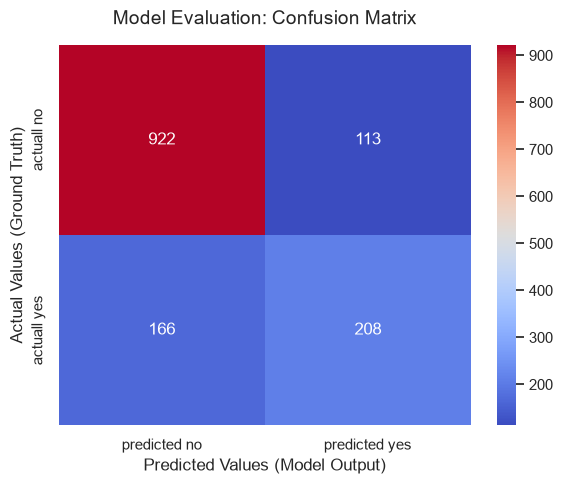

In [36]:
from sklearn.metrics import classification_report , confusion_matrix
RegressionModel.fit(XTrain , YTrain)
YPred=RegressionModel.predict(XTest)
test_results = {
    "F1": scoring['f1'](RegressionModel, XTest, YTest),
    "Recall": scoring['recall'](RegressionModel, XTest, YTest),
    "Precision": scoring['precision'](RegressionModel, XTest, YTest),
    "ROC-AUC": scoring['ROC-AUC'](RegressionModel, XTest, YTest),
    "accuracy" : RegressionModel.score(XTest , YTest)
}
print(pd.Series(test_results))
CM=confusion_matrix(YTest , YPred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    CM,
    annot=True,  # Put the numbers inside the squares
    fmt="d",  # Print integers instead of scientific notation
    cmap="coolwarm",  # Color gradient palette
    xticklabels=["predicted no" , "predicted yes"],
    yticklabels=["actuall no" , "actuall yes"],
    cbar=True,  # Show the color scale bar
)

# 4. Add clear labels and title
plt.title("Model Evaluation: Confusion Matrix", fontsize=14, pad=15)
plt.ylabel("Actual Values (Ground Truth)", fontsize=12)
plt.xlabel("Predicted Values (Model Output)", fontsize=12)

# 5. Display the matrix
plt.tight_layout()
plt.show()

test_f1           0.604825
 test_recall       0.555853
 test_precision    0.663607
 test_ROC-AUC      0.843387


The final model achieves test scores close to its cross-validation estimates. ROC-AUC is slightly higher, recall is nearly identical, and F1-score and precision are slightly lower. These results suggest that the model generalizes reasonably well to unseen data

our confusion matrix indicates that we have

True negatives : 922  non-churners correctly identified

False positive : 113 non churnered missed and precited as they will leave

False negative : 166 actuall churners missed  predicted as they will not go  

True Postive : 208 churners identified

we have Approximately 44.4% of actual churners are still missed

In [39]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "Logistic Regression (Tuned)",
        "Gradient Boosting (Tuned)"
    ],
    "Accuracy": [0.7346, 0.8076, 0.7288, 0.7888, 0.7909, 0.801987, None],
    "Precision": [0, 0.6648, 0.4888, 0.6323, 0.6311, 0.6636, 0.6667],
    "Recall": [0, 0.5545, 0.5003, 0.4876, 0.5104, 0.5559, 0.5264],
    "F1-score": [0, 0.6046, 0.4944, 0.5500, 0.5638, 0.6048, 0.5878],
    "ROC-AUC": [None, None, None, None, None, 0.8434, 0.8470]
})

model_comparison = model_comparison.sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

display(
    model_comparison.style
    .format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}",
        "ROC-AUC": "{:.2%}"
    }, na_rep="—")
    .highlight_max(subset=["F1-score"], color="green")
)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression (Tuned),80.20%,66.36%,55.59%,60.48%,84.34%
1,Logistic Regression,80.76%,66.48%,55.45%,60.46%,—
2,Gradient Boosting (Tuned),—,66.67%,52.64%,58.78%,84.70%
3,Gradient Boosting,79.09%,63.11%,51.04%,56.38%,—
4,Random Forest,78.88%,63.23%,48.76%,55.00%,—
5,Decision Tree,72.88%,48.88%,50.03%,49.44%,—
6,Dummy Classifier,73.46%,0.00%,0.00%,0.00%,—
